# Exercise 11: Noisy polynomial prediction with NN

### Premise: Single-neuron NN that models a linear function

Consider a noisy linear function $f(x) = 2x + 1 + \eta$ (*where $\eta$ is a gaussian noise component centered in $0$*), and generate two sets of its samples uniformly in $x \in [-1, 1)$: 
- the *training data*, used to optimize the NN parameters
- the *validation data* used to measure the predictive capabilities of the model

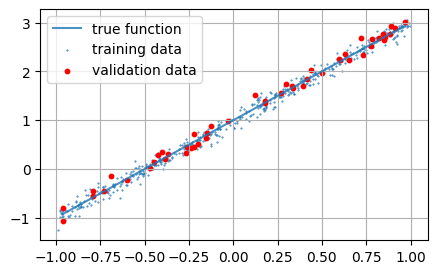

In [1]:
import numpy as np
import matplotlib.pyplot as plt

m = 2
q = 1

np.random.seed(0)
sigma = 0.1
x_train = np.random.uniform(-1, 1, 500)
y_train = np.random.normal(m * x_train + q, sigma)
x_valid = np.random.uniform(-1, 1, 50)
x_valid.sort()
y_valid = np.random.normal(m * x_valid + q, sigma)
y_target = m * x_valid + q # noiseless output of validation dataset, to 
                           # visualize the underlying function

fig, ax = plt.subplots(1, 1, figsize = (5, 3))
ax.plot(x_valid, y_target, label="true function", alpha = 0.8)
ax.scatter(x_train, y_train, label="training data", s=0.2)
ax.scatter(x_valid, y_valid, color='r', label="validation data", s=10.0)
ax.legend()
ax.grid(True)

We then define a 1-layer and 1-neuron only Sequential model with Tensorflow's Keras which, having 2 parameters (the neuron's weight and bias), shoud be able to predict our 2-parameters linear function:
$$ w_1 = m \qquad b = q $$

In [2]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras import backend as K
from tensorflow.keras.utils import get_custom_objects

model = tf.keras.Sequential() # sequential NN, for now empty of neurons/layers
model.add(Dense(1, input_shape=(1,))) # adds a dense layer with 1 neuron
                                      # being the first layer, we must specify the input shape
                                      # the default activation function is linear
model.compile(
    optimizer='sgd', # use stochastic gradient descent to optimize parameters
    loss='mse',      # aim to optimize mean squared error
    metrics=['mse']  # and report it as a performance metric
    )

model.summary()

I0000 00:00:1794489077.429734   11748 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794489077.479653   11748 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794489078.831714   11748 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/dario/coding/numerical_simulation_laboratory/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794489079.235333   11748 cuda_platform.cc:52] failed call to cuIni

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

Then we train this model using our *training data*: we can see its performance on the validation data as the training epochs progress

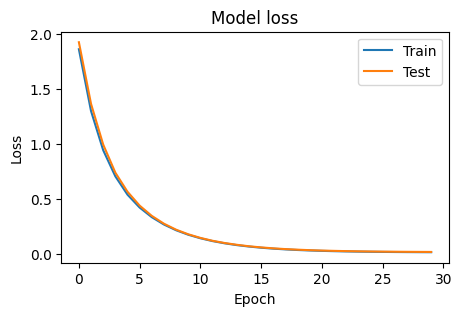

In [3]:
history = model.fit(
    x=x_train, y=y_train, # training data
    batch_size=32, # samples processed before each parameters update
    epochs=30,  # number of complete passes through the whole dataset
    shuffle=True, # randomize samples at each epoch
    validation_data=(x_valid, y_valid), # returns training history and 
                                        # performance after each epoch
    verbose=0
    )

fig, ax = plt.subplots(1, 1, figsize=(5,3))

ax.plot(history.history['loss'])
ax.plot(history.history['val_loss'])
ax.set_title('Model loss')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Test'], loc='best')

and evaluate its performance on both the *validation data* and the *target data*:

In [5]:
model.get_weights()

score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=0)

print()
print(f"Validation loss: {score[0]:.3e}")

score = model.evaluate(x_valid, y_target, batch_size=32, verbose=0)

print()
print(f"Target loss: {score[0]:.3e}")


Validation loss: 1.421e-02

Target loss: 2.085e-03


Now that the model is trained and validated, we can use it to predict the function's outputs on new $x$ values:

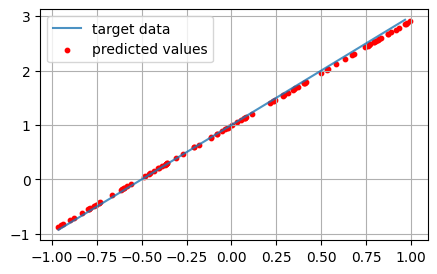

In [7]:
x_predict = np.random.uniform(-1, 1, 100)
y_predict = model.predict(x_predict, verbose=0)

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(x_valid, y_target, label="target data", alpha=0.8)
ax.scatter(x_predict, y_predict, color='r', label="predicted values", s=10.0)
ax.grid(True)
ax.legend()

### Ex.11.1: NN's dependence on parameters

> ***goal**: explore how these results vary (and can be improved by) changing the parameters: $N_{\text{epochs}}$, $N_{\text{train}}$, $\sigma$*

Let's generalize this process: after setting a list of values for $N$ and $\sigma$, we build a brand new *single-neuron* model for each, training it on its custom-built set of training and validation data. Then we evaluate performance on a universal set of *target noiseless data*.

In [9]:
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

def f(x):
    return 2*x + 1

def samples_set(N, sigma):
    x = np.random.uniform(-1, 1, N)
    return x, np.random.normal(f(x), sigma)

def build_model():
    model = tf.keras.Sequential()
    model.add(Input(shape=(1,)))
    model.add(Dense(1))
    model.compile(optimizer='sgd', loss='mse', metrics=['mse'])
    return model

epochs = 100    
N_validation = 100
x_target = np.random.uniform(-1, 1, N_validation)
y_target = f(x_target)

def training_results(sigma, N):
    tf.keras.backend.clear_session()
    tf.random.set_seed(0)

    # build the objects
    x_train, y_train = samples_set(N, sigma)
    x_valid, y_valid = samples_set(N_validation, sigma)
    model = build_model()
 
    # train the model
    history = model.fit(
        x_train, y_train,
        batch_size=32,
        epochs=epochs,
        shuffle=True,
        validation_data=(x_valid, y_valid),
        verbose=0
        )
            
    # save the training history
    w, b = model.get_weights()
    return {
        'sigma': sigma,
        'N': N,
        'w': w[0, 0], 'b': b[0],
        'loss': history.history['loss'],
        'val_loss': history.history['val_loss'],
        'mse_target': model.evaluate(x_target, y_target, batch_size=32, verbose=0)[0]
        }

sigma_list = [0.15, 0.3, 0.6, 1.2]
N_list = [150, 300, 600, 1200]

results = []
for sigma in sigma_list:
    for N in N_list:
        results.append( training_results(sigma, N) )

results = pd.DataFrame(results)


Then, having stored the whole training histories for all parameters combinations, we can plot them:
- the first row of plots compares the different training histories (their *training loss*) at different *sizes of the training set*; each plot corresponds to a different value of $\sigma$
- the second row does the opposite: compares the decreasing *training loss* for datasets with different $\sigma$, keeping $N_{training}$ fixed 

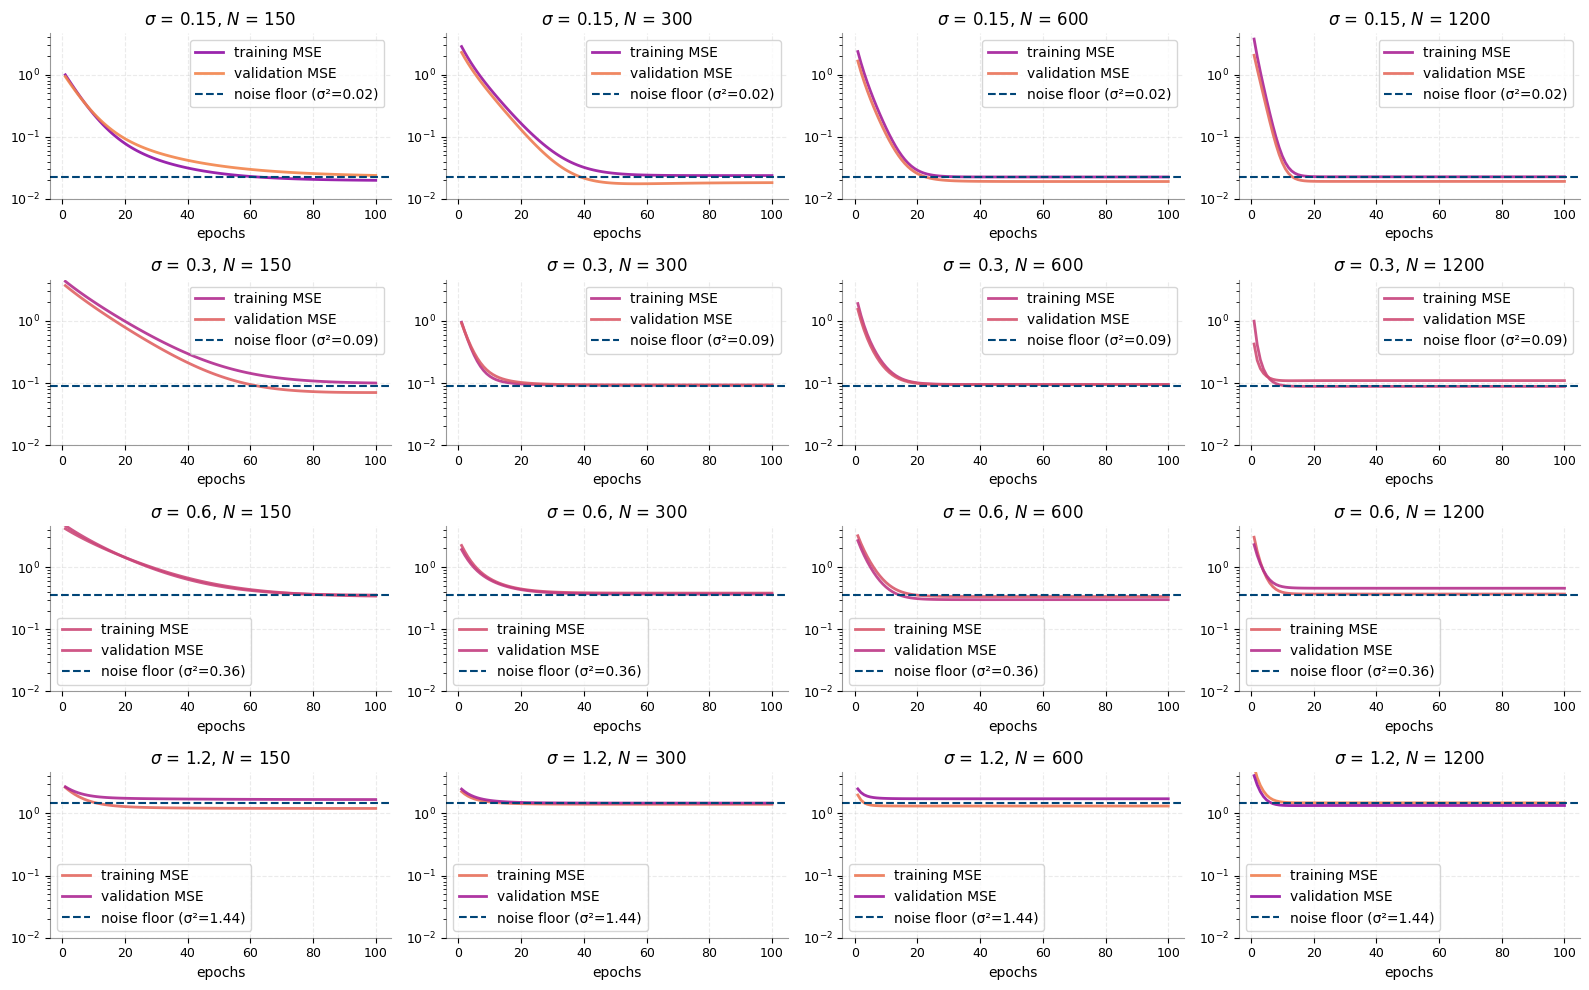

In [10]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(sigma_list), len(N_list), figsize=(4*len(sigma_list), 2.5*len(N_list)))

def style_ax(ax):
    ax.set_xlabel("epochs")
    ax.set_ylim(1e-2, 4.6)
    ax.set_yscale("log")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.25, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_alpha(0.4)
    ax.spines['bottom'].set_alpha(0.4)
    ax.tick_params(axis='both', labelsize=9)

def plt_loss(ax, results, sigma, N, color, color_val):
    subset = results.loc[(results['sigma'] == sigma) & (results['N'] == N)]
    loss = subset.iloc[0]['loss']
    val_loss = subset.iloc[0]['val_loss']        
    ax.plot(
        range(1, len(loss) + 1),
        loss,
        label="training MSE",
        color=color,
        lw=2,
        alpha=0.9
    )
    ax.plot(
        range(1, len(val_loss) + 1),
        val_loss,
        label="validation MSE",
        color=color_val,
        lw=2,
        alpha=0.9
    )
    ax.axhline(sigma**2, color='xkcd:prussian blue', ls='--', label=f'noise floor (σ²={sigma**2:.2f})')

for i in range(len(sigma_list)):
    colors = plt.cm.plasma(np.linspace(0.3, 0.7, 2*len(sigma_list)*len(N_list)))
    for j in range(len(N_list)):
        plt_loss(axs[i][j], results, sigma_list[i], N_list[j], colors[2*(len(sigma_list)*i + j)], colors[-2*(len(sigma_list)*i + j) - 1])
        axs[i][j].set_title(rf"$\sigma$ = {sigma_list[i]}, $N$ = {N_list[j]}")
        style_ax(axs[i][j])

fig.tight_layout()

#### Effects of training dataset size $N$ and noise $\sigma$
- larger training datasets ensure that, at similar numbers of epochs, the model converges faster (they actually processed a higher amount of datacompared to smaller models)
- conversely, smaller datasets are slower to converge (each epoch contains less data)
- the noise in training and validation $y$-values set a lower limit to both curves (estimated to be $\sigma^2$)

Note that with only 2 trainable parameters in the NN, we never risk overfitting our linear function.

Lastly, we at each loop iteration we checked the different performances against noiseless *target* data, and we can plot them on a 2D heatmap:

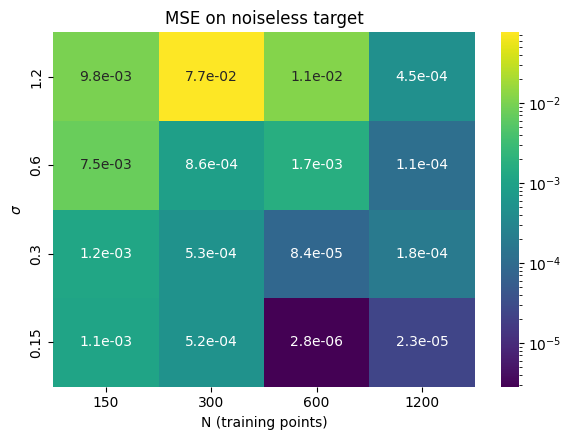

In [11]:
import seaborn as sns
from matplotlib.colors import LogNorm

pivot = results.pivot(
    index='sigma',  # each distinct sigma becomes a row
    columns='N',    # each distinct N becomes a column
    values='mse_target' #at each (sigma, N) pair the value is mse_target
    )
pivot = pivot.sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(pivot, annot=True, fmt='.1e', norm=LogNorm(), cmap='viridis')
ax.set_xlabel('N (training points)')
ax.set_ylabel(r'$\sigma$')
ax.set_title('MSE on noiseless target')

plt.tight_layout()
plt.show()

This heatmap loosely confirms that we achieve a better fit to the true linear function when we train our model with **large**, **low-noise** datasets, as expected.

### Ex.11.2: Fitting a polynomial
>***goal**: extend the previous model to fit*
> $$ f(x) = 3x^3 - 2x^2 - 3x + 4 $$
> *training it on samples within $[-1,1)$ with an appropriate level of noise.*
>
> *Choose an appropriate number of layers, neurons in each layer, activation function, optimizer algorithm, and loss function.*
>
> *Test the model by letting it predict values of $f(x)$ both within and outside the training interval.*

To see how different hidden layer shapes affect the outcome, we train different models on the same dataset (with noisy $y$-values for both training and validation data) and compare their predictions with noiseless polynomial samples *in* and *out* of their training interval:

In [12]:
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

np.random.seed(0)

def f(x):
    return 3*x**3 - 2*x**2 - 3*x + 4

def samples_set(N, sigma):
    x = np.random.uniform(-1, 1, N)
    return x, np.random.normal(f(x), sigma)

def build_model(shape):
    model = Sequential([Input(shape=(1,))])
    for neurons in shape:
        model.add(Dense(neurons, activation='tanh'))
    model.add(Dense(1, activation='linear'))
    model.compile(optimizer='adam', loss='mse', metrics=['mse'])
    return model

shapes = [  # to test different hidden layers shapes
    [1], [2], [4], [16], [64], [256],
    [8, 8], [6, 6, 6]
]
N = 500
epochs = 100
N_validation = 50
sigma = 0.1

# same training, validation and target sets for all
x_train, y_train = samples_set(N, sigma)
x_valid, y_valid = samples_set(N_validation, sigma)
x_target = np.random.uniform(-1.5, 1.5, N_validation)
y_target = f(x_target)
x_lattice = np.linspace(-1.5, 1.5, 300)
inside = np.abs(x_target) <= 1 # to distinguish in/out of the training interval

def training_results(shape):
    tf.keras.backend.clear_session()
    tf.random.set_seed(0)

    # build and train
    model = build_model(shape)
    history = model.fit(
        x_train, y_train,
        batch_size=32,
        epochs=epochs,
        shuffle=True,
        validation_data=(x_valid, y_valid),
        verbose=0
    )

    # save the training history
    return {
        'shape': str(shape),
        'width': shape[0], 
        'depth': len(shape), 
        'label': '-'.join(map(str, shape)),
        'params': model.count_params(),
        'loss': history.history['loss'][-1],
        'val_loss': history.history['val_loss'][-1],
        'grid_pred': model.predict(x_lattice, verbose=0).ravel(),
        'mse_in': model.evaluate(x_target[inside], y_target[inside], batch_size=32, verbose=0)[0],
        'mse_out': model.evaluate(x_target[~inside], y_target[~inside], batch_size=32, verbose=0)[0],
        'history': history.history
    }

results = []
for shape in shapes:
    results.append(training_results(shape))

results = pd.DataFrame(results)

Then we can compare the different NN architectures:

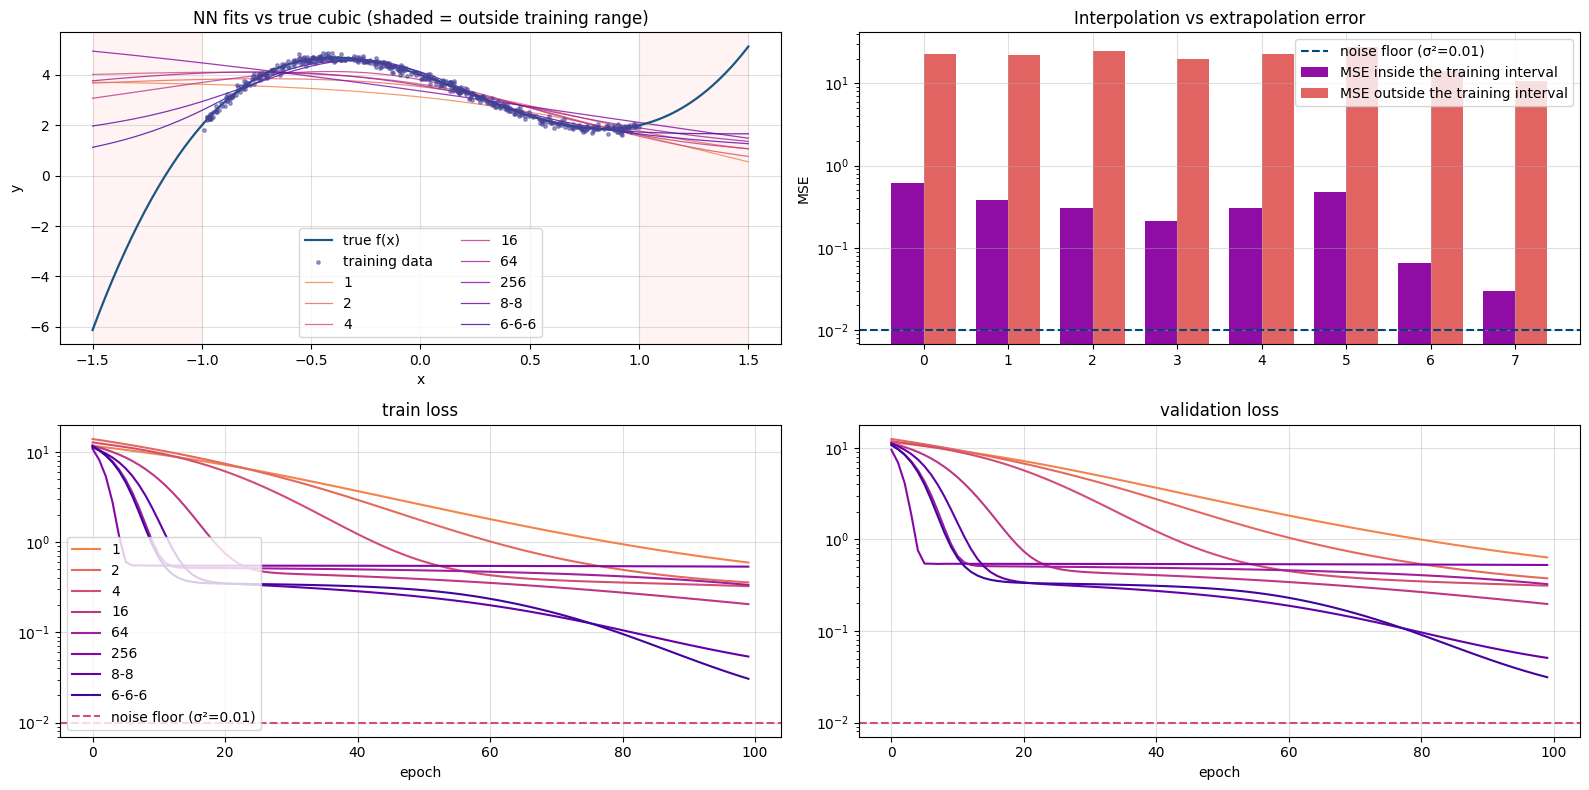

In [13]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(16, 8))

def plt_predictions(ax, results):
    colors = plt.cm.plasma_r(np.linspace(0.3, 0.9, len(results)))

    ax.plot(x_lattice, f(x_lattice), lw=1.6, color='xkcd:prussian blue', label='true f(x)', zorder=4, alpha=0.9) # true function
    ax.scatter(x_train, y_train, s=6, alpha=0.5, color='xkcd:blueberry', label='training data', zorder=5) # training data
    for (_, r), color in zip(results.iterrows(), colors):
        ax.plot(x_lattice, r['grid_pred'], label=r['label'], lw=0.9, alpha=0.8, color=color) # models predictions

    ax.axvspan(-1.5, -1, color='xkcd:salmon', alpha=0.08)   #inside region
    ax.axvspan(1, 1.5, color='xkcd:salmon', alpha=0.08)   # outside regions
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend(loc="best", ncol=2)
    ax.grid(True, alpha=0.4)
    ax.set_title('NN fits vs true cubic (shaded = outside training range)')

def plt_in_out_mse_comparison(ax, results):
    colors = plt.cm.plasma(np.linspace(0.3, 0.6, 2))
    idx = np.arange(len(results))
    w = 0.38
    ax.bar(idx - w/2, results['mse_in'],  w, label='MSE inside the training interval', color=colors[0])
    ax.bar(idx + w/2, results['mse_out'], w, label='MSE outside the training interval', color=colors[1])
    ax.axhline(sigma**2, color='xkcd:prussian blue', ls='--', label=f'noise floor (σ²={sigma**2:.2f})')
    ax.set_xticks(idx)
    ax.set_yscale('log'); ax.set_ylabel('MSE'); ax.legend(loc="best"); ax.grid(True, alpha=0.4)
    ax.set_title('Interpolation vs extrapolation error')

def plt_loss_history(ax_train, ax_valid, results):
    colors = plt.cm.plasma_r(np.linspace(0.3, 0.9, len(results)))
    
    for (_, r), color in zip(results.iterrows(), colors):
        ax_train.plot(r['history']['loss'], label=r['label'], color=color)
        ax_valid.plot(r['history']['val_loss'], label=r['label'], color=color)
    for a in [ax_train, ax_valid]: 
        a.set_yscale('log')
        a.set_xlabel('epoch')
        a.grid(True, alpha=0.4)
        a.axhline(sigma**2, color=colors[2], ls='--', label=f'noise floor (σ²={sigma**2:.2f})')
    ax_train.set_title('train loss'); ax_valid.set_title('validation loss')
    ax_train.legend(loc="best")

plt_predictions(axs[0][0], results)
plt_in_out_mse_comparison(axs[0][1], results)
plt_loss_history(axs[1][0], axs[1][1], results)
fig.tight_layout()

### Ex.11.3: Fitting a 2D trigonometric function
>***goal**: extend the model to fit an $\mathbb{R}^2$ function such as*
> $$ f(x, y) = sin(x^2 + y^2) $$
> training it on samples within $[-\frac{3}{2}, \frac{3}{2}) \times [-\frac{3}{2}, \frac{3}{2})$.

Since this $\mathbb{R}^2 \mapsto \mathbb{R}$ function exhibits rotational symmetry, it could be interesting to compare two models:
- one is simply taking samples in $[-L, L]^2$ and tries to build a fit for $f_{\mathbb{R}^2} : [-L,L] \mapsto [-1, 1]$
- the other, by converting each $(x_1, x_2)$ sample point to a single value $r$, is essentially a $f_{\mathbb{R}} : [0, L] \mapsto [-1, 1]$ fit

where both models are built with the same $8-16-8$ dense hidden layers structure: the only structural dfference is the first layer accepting a different number of inputs. 

We can start from the same training and validation sample sets for each: note that this creates, for the second model, a *non-uniform* distribution of samples in its $[0, L]$ domain.

In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

np.random.seed(0)

def f(r):
    return np.sin(r**2)

def samples_sets(N, L, sigma):
    x = np.random.uniform(-L, L, (N, 2))
    r = np.sqrt(np.sum(x*x, axis=1))
    return x, r.reshape(-1, 1), np.random.normal(f(r), sigma)

def build_model(d):
    model = Sequential([Input(shape=(d,))])
    model.add(Dense(8, activation='tanh'))
    model.add(Dense(16, activation='tanh'))
    model.add(Dense(8, activation='tanh'))
    model.add(Dense(1, activation='linear'))
    model.compile(optimizer='adam', loss='mse', metrics=['mse'])
    return model

N = 1500    # training samples
N_validation = 500
sigma = 0.15
L, L_ext = 1.5, 2.5

x_train, r_train,  y_train = samples_sets(N, L, sigma)
x_valid, r_valid, y_valid = samples_sets(N_validation, L, sigma)
x_target = np.random.uniform(-L_ext, L_ext, (N, 2))
r_target = np.sqrt(np.sum(x_target**2, axis=1)).reshape(-1, 1)
y_target = f(r_target)

inside = np.all(np.abs(x_target) <= L, axis=1)

def build_and_train(d, train, valid, target):
    tf.keras.backend.clear_session()
    tf.random.set_seed(0)

    model = build_model(d)
    history = model.fit(
        train, y_train,
        batch_size=32, epochs=200, shuffle=True,
        validation_data=(valid, y_valid), verbose=0
    )

    sq_err = (model.predict(target, verbose=0).ravel() - y_target.ravel())**2

    res = pd.DataFrame([{
        'loss': history.history['loss'][-1],
        'val_loss': history.history['val_loss'][-1],
        'mse_in': sq_err[inside].mean(),
        'mse_out': sq_err[~inside].mean(),
        'history': history.history
    }])
    return model, res

model_1d, results_1d = build_and_train(1, r_train, r_valid, r_target)
model_2d, results_2d = build_and_train(2, x_train, x_valid, x_target)

print(results_1d.drop(columns='history'))
print(results_2d.drop(columns='history'))

       loss  val_loss    mse_in  mse_out
0  0.022735  0.024432  0.001588   3.9181
       loss  val_loss    mse_in  mse_out
0  0.023172  0.025766  0.003863  1.48814


After having recorded, on top of each trained model, its training history and its performance on noiseless target data, we can plot and compare:

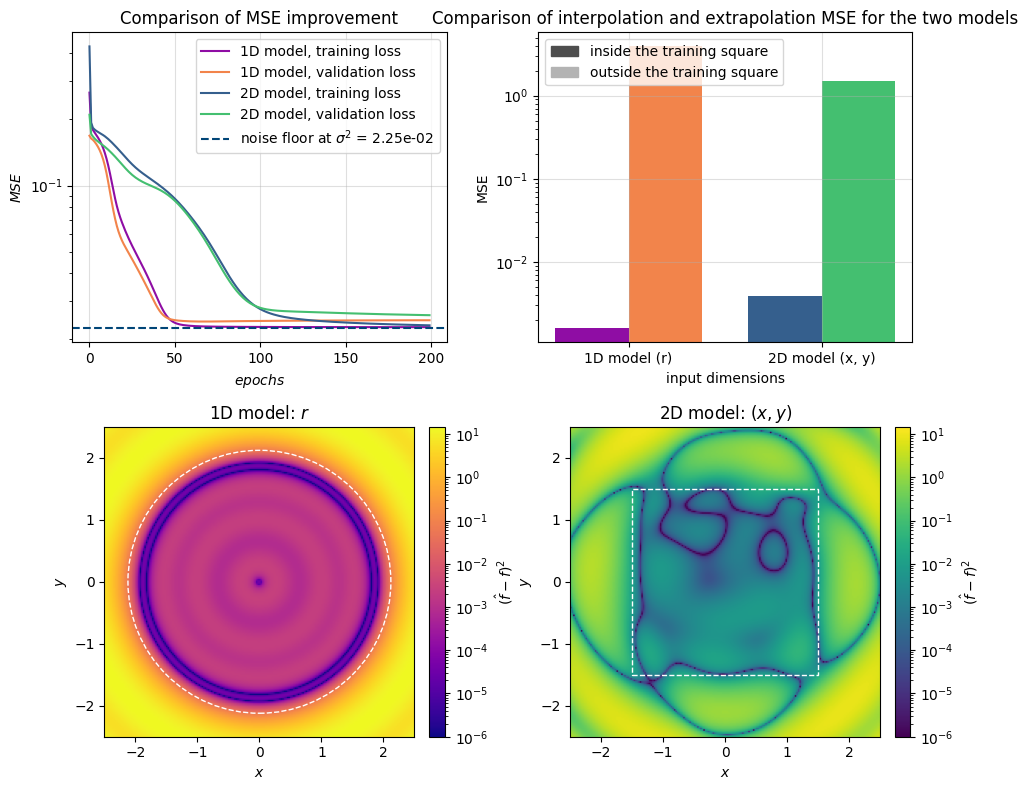

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from matplotlib.patches import Rectangle, Circle

def plt_losses(ax):
    h1d = results_1d['history'].iloc[0]
    h2d = results_2d['history'].iloc[0]
    colors_1d = plt.cm.plasma(np.linspace(0.3, 0.7, 2))
    colors_2d = plt.cm.viridis(np.linspace(0.3, 0.7, 2))

    ax.plot(h1d['loss'], color=colors_1d[0], label="1D model, training loss")
    ax.plot(h1d['val_loss'], color=colors_1d[1], label="1D model, validation loss")
    ax.plot(h2d['loss'], color=colors_2d[0], label="2D model, training loss")
    ax.plot(h2d['val_loss'], color=colors_2d[1], label="2D model, validation loss")
    ax.axhline(sigma**2, ls='--', color='xkcd:prussian blue', label=rf"noise floor at $\sigma^2$ = {sigma*sigma:.2e}")

    ax.set_title("Comparison of MSE improvement")
    ax.set_xlabel(r"$epochs$"); ax.set_ylabel(r"$MSE$")
    ax.set_yscale("log")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.4)

def plt_in_out_accuracy(ax):
    mse = {'1D model (r)': (results_1d['mse_in'].iloc[0], results_1d['mse_out'].iloc[0]),
           '2D model (x, y)': (results_2d['mse_in'].iloc[0], results_2d['mse_out'].iloc[0])}
    cmaps = [plt.cm.plasma, plt.cm.viridis]

    idx = np.arange(1, 3)
    w = 0.38
    for i, (cm, (m_in, m_out)) in enumerate(zip(cmaps, mse.values())):
        ax.bar(idx[i] - w/2, m_in,  w, color=cm(0.3))
        ax.bar(idx[i] + w/2, m_out, w, color=cm(0.7))

    ax.set_xticks(idx)
    ax.set_xticklabels(list(mse.keys()))
    ax.set_title("Comparison of interpolation and extrapolation MSE for the two models")
    ax.set_yscale("log")
    ax.set_xlabel("input dimensions"); ax.set_ylabel("MSE")
    ax.grid(True, alpha=0.4)
    ax.legend(handles=[Patch(color='0.3', label='inside the training square'),
                       Patch(color='0.7', label='outside the training square')],
              loc="best")

def plt_maps(ax1d, ax2d):
    g = np.linspace(-L_ext, L_ext, 200)
    X1, X2 = np.meshgrid(g, g)
    grid = np.column_stack([X1.ravel(), X2.ravel()])
    r_grid = np.sqrt(np.sum(grid**2, axis=1))
    true = f(r_grid)

    err_1d = (model_1d.predict(r_grid.reshape(-1, 1), verbose=0).ravel() - true)**2
    err_2d = (model_2d.predict(grid, verbose=0).ravel() - true)**2
    vmin, vmax = 1e-6, max(err_1d.max(), err_2d.max())

    im1d = ax1d.imshow(np.clip(err_1d, vmin, None).reshape(X1.shape), origin='lower',
                     extent=[-L_ext, L_ext, -L_ext, L_ext],
                     norm=LogNorm(vmin=vmin, vmax=vmax), cmap='plasma')
    ax1d.add_patch(Circle((0, 0), L*np.sqrt(2), fill=False, ec='w', ls='--'))
    ax1d.set_title("1D model: $r$")
    ax1d.set_xlabel(r"$x$"); ax1d.set_ylabel(r"$y$")

    im2d = ax2d.imshow(np.clip(err_2d, vmin, None).reshape(X1.shape), origin='lower',
                     extent=[-L_ext, L_ext, -L_ext, L_ext],
                     norm=LogNorm(vmin=vmin, vmax=vmax), cmap='viridis')
    ax2d.add_patch(Rectangle((-L, -L), 2*L, 2*L, fill=False, ec='w', ls='--'))
    ax2d.set_title("2D model: $(x, y)$")
    ax2d.set_xlabel(r"$x$"); ax2d.set_ylabel(r"$y$")

    fig.colorbar(im1d, ax=ax1d, label=r"$(\hat f - f)^2$", fraction=0.046, pad=0.04)
    fig.colorbar(im2d, ax=ax2d, label=r"$(\hat f - f)^2$", fraction=0.046, pad=0.04)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

plt_losses(axs[0][0])
plt_in_out_accuracy(axs[0][1])
plt_maps(axs[1][0], axs[1][1])
fig.tight_layout()

This comparison highlights that
- inside the training region the model that takes advantage of rotational simmetry converges much faster and reaches its maximum accuracy (*set by the data's noise level*) much earlier
- outside of the training region both models' accuracy rapidly decreases in a similar way (*this highlights a poor choice in the network's activation functions*)
- the effective '*inside*' region for the reduced model $(r)$ extends a bit further than the square that delimited the initial dataset